# 01-audit: Phase 0 data audit

First look at the competition data. The exact file layout is not assumed:
Part 1 inventories whatever is attached and always writes its output, Part 2
loads the subjects, Part 3 shows what one sample looks like, and Part 4
measures what Phase 1 needs (T, cleaning state, AR structure, ICN order, and
which M and Delta the scans can support).

**To run:** attach the competition data, then Save Version > Save & Run All.
Everything lands in `/kaggle/working/01-audit-results.zip`. Put that zip in
the local `Results` folder. A failed section is logged to `errors.txt` and the
run carries on, so one surprise in the data does not cost the whole run.

In [1]:
import hashlib
import json
import logging
import os
import pickle
import re
import shutil
import subprocess
import sys
import time
import traceback
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.cluster.hierarchy as sch
import scipy.io
import scipy.signal
import scipy.stats as ss
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import adjusted_rand_score
from tqdm.auto import tqdm

SEED = 20261030
rng = np.random.default_rng(SEED)

INPUT_ROOT = Path(os.environ.get("DFCPD_INPUT", "/kaggle/input"))
WORK_ROOT = Path(os.environ.get("DFCPD_WORKING", "/kaggle/working"))
OUT = WORK_ROOT / "01-audit"
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

P = 105
N_EDGES = P * (P - 1) // 2
M_GRID = (30, 60, 100)
DELTA_GRID = (30, 60, 120)
ACF_LAGS = 20
EXPECTED_COUNTS = {"SZ": 288, "BP": 183, "test": 315}
COVARIATE_WORDS = ("motion", "fd", "framewise", "dvars", "site", "scanner", "age", "sex",
                   "gender", "tr", "repetition", "tesla", "center", "centre")

logging.basicConfig(level=logging.INFO, format="%(asctime)s %(message)s", stream=sys.stdout, force=True)
log = logging.getLogger("audit")
log.info("seed=%d input=%s output=%s", SEED, INPUT_ROOT, OUT)

(OUT / "pip_freeze.txt").write_text(
    subprocess.run([sys.executable, "-m", "pip", "freeze"], capture_output=True, text=True).stdout
)

SUMMARY = {"seed": SEED, "sections_failed": []}
STATE = {"ready": False}


def step(fn):
    """Run a section now; skip it if the data never loaded, and keep going if it fails."""
    if fn.__name__ != "inventory" and not STATE["ready"] and not getattr(fn, "always", False):
        log.info("SKIP %s (subjects not loaded)", fn.__name__)
        return fn
    log.info("START %s", fn.__name__)
    t0 = time.time()
    try:
        fn()
        log.info("DONE  %s (%.1fs)", fn.__name__, time.time() - t0)
    except Exception:
        SUMMARY["sections_failed"].append(fn.__name__)
        with open(OUT / "errors.txt", "a") as f:
            f.write(f"--- {fn.__name__} ---\n{traceback.format_exc()}\n")
        log.exception("FAILED %s", fn.__name__)
    return fn


def always(fn):
    fn.always = True
    return fn

2026-10-30 23:06:05,729 seed=20261030 input=/kaggle/input output=/kaggle/working/01-audit


In [2]:
SZ_COLOR, BP_COLOR = "#2a78d6", "#eb6834"
GROUP_COLORS = {"SZ": SZ_COLOR, "BP": BP_COLOR}
INK, MUTED, GRID = "#2b2b29", "#6f6e69", "#e4e2dc"
SEQ_BLUE = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#6da7ec", "#2a78d6", "#184f95", "#0d366b"])
DIV_FNC = LinearSegmentedColormap.from_list("div_fnc", ["#184f95", "#6da7ec", "#f0efec", "#ec8a8a", "#b52f2f"])

plt.rcParams.update({
    "figure.dpi": 130, "savefig.bbox": "tight", "font.size": 9, "axes.titlesize": 10,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.edgecolor": GRID,
    "axes.labelcolor": MUTED, "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "lines.linewidth": 2, "legend.frameon": False,
})


def save_fig(fig, name):
    fig.savefig(FIG / f"{name}.png")
    plt.show()
    plt.close(fig)

## Part 1: what is in the competition data?

In [3]:
def read_any(path):
    """Return {key: array} for a data file, or {} for formats we only list."""
    ext = path.suffix.lower()
    if ext == ".npy":
        try:
            return {"": np.load(path, allow_pickle=False)}
        except ValueError:
            return {"": np.load(path, allow_pickle=True)}
    if ext == ".npz":
        with np.load(path, allow_pickle=True) as z:
            return {k: z[k] for k in z.files}
    if ext == ".mat":
        try:
            return {k: v for k, v in scipy.io.loadmat(path).items() if not k.startswith("__")}
        except NotImplementedError:
            return read_hdf5(path)
    if ext in (".h5", ".hdf5"):
        return read_hdf5(path)
    if ext in (".pkl", ".pickle"):
        with open(path, "rb") as f:
            obj = pickle.load(f)
        return obj if isinstance(obj, dict) else {"": obj}
    return {}


def read_hdf5(path):
    import h5py
    out = {}
    with h5py.File(path, "r") as f:
        f.visititems(lambda k, v: out.__setitem__(k, v[()]) if isinstance(v, h5py.Dataset) else None)
    return out


def describe(value):
    arr = np.asarray(value) if not isinstance(value, dict) else None
    if arr is None:
        return f"dict with keys {list(value)[:10]}"
    text = f"shape={arr.shape} dtype={arr.dtype}"
    if arr.dtype.kind in "fiub" and arr.size:
        finite = arr[np.isfinite(arr)] if arr.dtype.kind == "f" else arr
        if finite.size:
            text += f" min={finite.min():.4g} max={finite.max():.4g} mean={finite.mean():.4g} std={finite.std():.4g}"
        text += f" nonfinite={arr.size - finite.size}"
    return text


def path_pattern(rel):
    """Collapse ID-like names so the layout shows up as a few lines."""
    parts = list(Path(rel).parts)
    collapsed = ["#" if re.search(r"\d", part) else part for part in parts[:-1]]
    name = parts[-1]
    collapsed.append(("#" + Path(name).suffix) if re.search(r"\d", Path(name).stem) else name)
    return "/".join(collapsed)


@step
def inventory():
    files = sorted(p for p in INPUT_ROOT.rglob("*") if p.is_file())
    table = pd.DataFrame({
        "path": [str(p.relative_to(INPUT_ROOT)) for p in files],
        "ext": [p.suffix.lower() for p in files],
        "bytes": [p.stat().st_size for p in files],
    })
    table["pattern"] = [path_pattern(p) for p in table["path"]]
    table.to_csv(OUT / "file_inventory.csv", index=False)
    patterns = table.groupby("pattern").agg(n=("path", "size"), mb=("bytes", lambda b: b.sum() / 1e6))
    patterns = patterns.sort_values("n", ascending=False)
    patterns.to_csv(OUT / "file_patterns.csv")
    log.info("%d files, %.1f MB\n%s", len(table), table["bytes"].sum() / 1e6, patterns.head(40).to_string())

    lines = []
    for pattern, group in table.groupby("pattern"):
        for rel in group["path"].head(3):
            path = INPUT_ROOT / rel
            lines.append(f"\n{rel} ({path.stat().st_size / 1e6:.2f} MB)")
            if path.suffix.lower() in (".csv", ".tsv"):
                df = pd.read_csv(path, sep="\t" if path.suffix.lower() == ".tsv" else ",", nrows=5)
                lines.append(f"  columns ({df.shape[1]}): {list(df.columns)[:40]}")
                lines.append(df.iloc[:, :12].to_string())
            elif path.suffix.lower() in (".txt", ".md", ".json", ".yaml", ".yml"):
                lines.append("\n".join(path.read_text(errors="replace").splitlines()[:30]))
            else:
                try:
                    for key, value in read_any(path).items():
                        lines.append(f"  [{key}] {describe(value)}")
                except Exception as err:
                    lines.append(f"  could not read: {err}")
    text = "\n".join(lines)
    (OUT / "file_samples.txt").write_text(text)
    log.info(text[:6000])

    covariates = []
    for rel in table.loc[table["ext"].isin([".csv", ".tsv"]), "path"]:
        path = INPUT_ROOT / rel
        cols = pd.read_csv(path, sep="\t" if path.suffix.lower() == ".tsv" else ",", nrows=0).columns
        for col in cols:
            tokens = re.split(r"[^a-z0-9]+", str(col).lower())
            if any(word in tokens for word in COVARIATE_WORDS):
                covariates.append({"file": rel, "column": col})
    SUMMARY["n_files"] = len(table)
    SUMMARY["file_patterns"] = patterns.head(15)["n"].to_dict()
    SUMMARY["covariate_columns_found"] = covariates
    log.info("covariate-like columns: %s", covariates or "none")

2026-10-30 23:06:09,424 START inventory
2026-10-30 23:06:16,860 3144 files, 201.0 MB
                                                                                n         mb
pattern                                                                                     
competitions/psychosis-classification-with-rsfmri/data/test/#/fnc.mat         315  13.278940
competitions/psychosis-classification-with-rsfmri/data/test/#/fnc.npy         315  13.799520
competitions/psychosis-classification-with-rsfmri/data/test/#/icn_tc.mat      315  25.831727
competitions/psychosis-classification-with-rsfmri/data/test/#/icn_tc.npy      315  27.745200
competitions/psychosis-classification-with-rsfmri/data/train/SZ/#/icn_tc.npy  288  25.312464
competitions/psychosis-classification-with-rsfmri/data/train/SZ/#/icn_tc.mat  288  23.569346
competitions/psychosis-classification-with-rsfmri/data/train/SZ/#/fnc.npy     288  12.616704
competitions/psychosis-classification-with-rsfmri/data/train/SZ/#/fnc.mat     

In [4]:
def classify(arr):
    """Name a numeric array as a time-course or FNC by its shape alone."""
    arr = np.squeeze(arr)
    if arr.dtype.kind not in "fiu":
        return None, None
    if arr.ndim == 1 and arr.size == N_EDGES:
        return "fnc", arr
    if arr.ndim == 2 and arr.shape == (P, P):
        if np.allclose(arr, arr.T, equal_nan=True):
            return "fnc", arr
        return "tc", arr
    if arr.ndim == 2 and arr.shape[1] == P:
        return "tc", arr
    if arr.ndim == 2 and arr.shape[0] == P:
        return "tc", arr.T
    return None, None


def subject_id(path, key):
    stem = re.sub(r"(?i)time_?courses?|icn|fnc|tcs?(?=$|[_-])", "", path.stem).strip("_- ")
    return stem or path.parent.name


def path_hints(path):
    parts = [part.lower() for part in path.parts]
    label = None
    for part in parts:
        if part in ("sz", "schizophrenia"):
            label = "SZ"
        elif part in ("bp", "bpp", "bipolar"):
            label = "BP"
    split = "test" if "test" in parts else "train" if "train" in parts else ("train" if label else None)
    return split, label


def labels_from_tables(ids):
    """Find a table with one column of subject IDs and one binary column."""
    ids = set(map(str, ids))
    for path in sorted(INPUT_ROOT.rglob("*.csv")):
        if re.search(r"(?i)submission|sample", path.name):
            continue
        df = pd.read_csv(path, dtype=str)
        for id_col in df.columns:
            if df[id_col].isin(ids).sum() < 0.5 * len(df) or df[id_col].isin(ids).sum() == 0:
                continue
            for label_col in df.columns.drop(id_col):
                values = df[label_col].dropna().unique()
                if len(values) != 2:
                    continue
                mapping = {v: ("SZ" if "SZ" in v.upper() or "SCHIZ" in v.upper() else "BP") for v in values}
                source = f"{path.name}:{label_col}"
                if not any(re.search(r"(?i)sz|schiz", v) for v in values):
                    counts = df[label_col].value_counts()
                    mapping = {counts.index[0]: "SZ", counts.index[1]: "BP"}
                    source += " (mapped by class size, confirm against the data page)"
                log.info("labels from %s: %s", source, mapping)
                SUMMARY["label_source"] = source
                return dict(zip(df[id_col], df[label_col].map(mapping)))
    return {}


TC, FNC, META = {}, {}, {}


@step
@always
def load_subjects():
    files = [p for p in INPUT_ROOT.rglob("*") if p.is_file()
             and p.suffix.lower() in (".npy", ".npz", ".mat", ".h5", ".hdf5", ".pkl", ".pickle")]
    skipped = []
    for path in tqdm(files, desc="load"):
        try:
            contents = read_any(path)
        except Exception as err:
            skipped.append((str(path), str(err)))
            continue
        for key, value in contents.items():
            kind, arr = classify(np.asarray(value))
            if kind is None:
                continue
            sid = subject_id(path, key)
            split, label = path_hints(path)
            store = TC if kind == "tc" else FNC
            if sid in store:
                SUMMARY.setdefault("duplicate_subject_files", []).append(str(path))
                continue
            store[sid] = arr.astype(np.float64)
            META.setdefault(sid, {"subject": sid, "split": split, "label": label, "dtype": str(arr.dtype),
                                  "tc_file": None})
            if kind == "tc":
                META[sid]["tc_file"] = str(path.relative_to(INPUT_ROOT))
    if skipped:
        log.info("unreadable files: %d, first: %s", len(skipped), skipped[0])
    log.info("loaded time-courses=%d fnc=%d", len(TC), len(FNC))

    if TC and not any(m["label"] for m in META.values()):
        labels = labels_from_tables(TC)
        for sid, label in labels.items():
            if sid in META:
                META[sid]["label"], META[sid]["split"] = label, "train"
    else:
        SUMMARY.setdefault("label_source", "folder names")
    for meta in META.values():
        meta["split"] = meta["split"] or ("train" if meta["label"] else "test")

    if not TC:
        log.warning("No T x 105 arrays were recognised. Send back file_patterns.csv and file_samples.txt.")
        return
    STATE["ready"] = True
    counts = pd.DataFrame(META.values()).fillna({"label": "none"}).value_counts(["split", "label"])
    log.info("subjects by split and label:\n%s", counts.to_string())
    SUMMARY["subject_counts"] = {"/".join(k): int(v) for k, v in counts.items()}
    n = pd.Series([m["label"] or m["split"] for m in META.values() if m["subject"] in TC]).value_counts()
    SUMMARY["expected_vs_found"] = {k: {"expected": v, "found": int(n.get(k, 0))} for k, v in EXPECTED_COUNTS.items()}
    log.info("expected vs found: %s", SUMMARY["expected_vs_found"])

2026-10-30 23:06:17,181 START load_subjects


load:   0%|          | 0/3144 [00:00<?, ?it/s]

2026-10-30 23:06:39,048 loaded time-courses=786 fnc=786
2026-10-30 23:06:39,059 subjects by split and label:
split  label
test   none     315
train  SZ       288
       BP       183
2026-10-30 23:06:39,062 expected vs found: {'SZ': {'expected': 288, 'found': 288}, 'BP': {'expected': 183, 'found': 183}, 'test': {'expected': 315, 'found': 315}}
2026-10-30 23:06:39,063 DONE  load_subjects (21.9s)


## Part 2: per-subject measurements

One pass over every subject builds the tables the later sections read:
scaling, missing values, tails, autocorrelation, drift and duplicates.

In [5]:
def acf_matrix(x, n_lags):
    """Sample ACF, shape (n_lags, p), on a demeaned T x p array."""
    denom = (x ** 2).sum(0)
    denom = np.where(denom > 0, denom, np.nan)
    return np.stack([(x[:-k] * x[k:]).sum(0) / denom for k in range(1, n_lags + 1)])


def drift_stats(x):
    """Linear trend per ICN, with a t-test widened by the residual AR(1)."""
    T = len(x)
    t = np.arange(T) - (T - 1) / 2
    slope = (t[:, None] * x).sum(0) / (t ** 2).sum()
    resid = x - t[:, None] * slope
    sse = (resid ** 2).sum(0)
    r2 = 1 - sse / np.where((x ** 2).sum(0) > 0, (x ** 2).sum(0), np.nan)
    r1 = np.clip(acf_matrix(resid, 1)[0], -0.95, 0.95)
    n_eff = np.maximum(T * (1 - r1) / (1 + r1), 4.0)
    se = np.sqrt(sse / (T - 2) / (t ** 2).sum() * (T / n_eff))
    return r2, 2 * ss.t.sf(np.abs(slope / se), n_eff - 2)


def edge_ess_ratio(acf, T):
    """Bartlett n_eff / T for uncorrelated edges, with a Tukey taper on the ACF."""
    L = min(ACF_LAGS, T // 4)
    taper = 0.5 * (1 + np.cos(np.pi * np.arange(1, L + 1) / (L + 1)))
    weighted = acf[:L] * np.sqrt(taper)[:, None]
    inflation = 1 + 2 * weighted.T @ weighted
    return np.median(1 / np.maximum(inflation[np.triu_indices(P, 1)], 1.0))


FEATURES = {}
QC = None


@step
def per_subject_table():
    global QC
    rows = []
    ids = sorted(TC)
    keys = ("ar1", "ar1_bc", "ar2_phi2", "excess_kurtosis", "icn_mean", "icn_std", "drift_r2", "drift_p")
    arrays = {k: np.full((len(ids), P), np.nan) for k in keys}
    acf_mean = np.zeros((ACF_LAGS, P))
    n_acf = 0
    for i, sid in enumerate(tqdm(ids, desc="qc")):
        raw = TC[sid]
        T = len(raw)
        finite = np.isfinite(raw)
        std = np.nanstd(raw, axis=0)
        row = {**META[sid], "T": T, "n_nonfinite": int((~finite).sum()), "n_constant_icns": int((std < 1e-10).sum()),
               "max_abs": float(np.nanmax(np.abs(raw))),
               "hash": hashlib.sha1(np.nan_to_num(raw).tobytes()).hexdigest()}
        usable = row["n_nonfinite"] == 0 and row["n_constant_icns"] == 0 and T > 2 * ACF_LAGS
        row["usable"] = usable
        rows.append(row)
        arrays["icn_mean"][i], arrays["icn_std"][i] = np.nanmean(raw, axis=0), std
        if not usable:
            continue
        x = raw - raw.mean(0)
        acf = acf_matrix(x, ACF_LAGS)
        r1, r2 = acf[0], acf[1]
        arrays["ar1"][i] = r1
        arrays["ar1_bc"][i] = r1 + (1 + 3 * r1) / T
        arrays["ar2_phi2"][i] = (r2 - r1 ** 2) / (1 - r1 ** 2)
        arrays["excess_kurtosis"][i] = ss.kurtosis(x, axis=0)
        arrays["drift_r2"][i], arrays["drift_p"][i] = drift_stats(x)
        acf_mean += acf
        n_acf += 1
        rows[-1]["ess_ratio"] = edge_ess_ratio(acf, T)
    QC = pd.DataFrame(rows).drop(columns="tc_file")
    FEATURES.update(arrays, ids=ids, acf_mean=acf_mean / max(n_acf, 1))
    QC["mean_ar1_bc"] = np.nanmean(arrays["ar1_bc"], axis=1)
    QC["median_kurtosis"] = np.nanmedian(arrays["excess_kurtosis"], axis=1)
    QC["drift_frac_p05"] = np.nanmean(arrays["drift_p"] < 0.05, axis=1)
    QC["mean_abs_icn_mean"] = np.nanmean(np.abs(arrays["icn_mean"]), axis=1)
    QC["mean_icn_std"] = np.nanmean(arrays["icn_std"], axis=1)
    QC.to_csv(OUT / "subject_qc.csv", index=False)

    dup = QC[QC.duplicated("hash", keep=False)]
    SUMMARY["data_quality"] = {
        "subjects": len(QC), "usable": int(QC["usable"].sum()),
        "with_nonfinite": int((QC["n_nonfinite"] > 0).sum()),
        "with_constant_icn": int((QC["n_constant_icns"] > 0).sum()),
        "duplicate_scans": len(dup), "dtypes": QC["dtype"].value_counts().to_dict(),
    }
    log.info("%s", SUMMARY["data_quality"])

2026-10-30 23:06:39,112 START per_subject_table


qc:   0%|          | 0/786 [00:00<?, ?it/s]

2026-10-30 23:06:43,161 {'subjects': 786, 'usable': 786, 'with_nonfinite': 0, 'with_constant_icn': 0, 'duplicate_scans': 10, 'dtypes': {'float64': 786}}
2026-10-30 23:06:43,162 DONE  per_subject_table (4.0s)


## Part 3: what does one sample look like?

Each sample is one person's resting-state fMRI scan, already reduced by ICA
from a brain volume at every time point to 105 intrinsic connectivity network
(ICN) signals.

- **Time-courses:** a T x 105 table. Each row is one volume (one TR) and each
  column is one network. T differs between people.
- **FNC:** the 105 x 105 correlation between those columns, which has 5,460
  unique edges. It summarises the whole scan as a single number per edge.
- **Label:** SZ or BP, for the labelled subjects only.

FNC assumes connectivity holds still for the entire scan. This project asks
whether it does, so the time-courses are the input and FNC is the baseline.

The examples below are the labelled subjects closest to the median scan
length, so they are typical in length and not chosen for how they look. One
subject per group is shown only to see the data, and two people say nothing
about the groups.

In [6]:
EXAMPLES = {}


def zscore(x):
    return (x - x.mean(0)) / x.std(0)


@step
def choose_examples():
    used = QC[QC["usable"]]
    for group in GROUP_COLORS:
        pool = used[used["label"] == group]
        if len(pool):
            distance = (pool["T"] - pool["T"].median()).abs()
            EXAMPLES[group] = pool.assign(distance=distance).sort_values(["distance", "subject"])["subject"].iloc[0]
    if not EXAMPLES:
        EXAMPLES["unlabelled"] = used.sort_values("subject")["subject"].iloc[0]
    SUMMARY["example_subjects"] = EXAMPLES

    table = QC.assign(label=QC["label"].fillna("none")).groupby(["split", "label"]).agg(
        subjects=("subject", "size"), T_min=("T", "min"), T_median=("T", "median"), T_max=("T", "max"))
    table.to_csv(OUT / "sample_overview.csv")
    print("All samples:\n", table.to_string(), "\n", sep="")

    for group, sid in EXAMPLES.items():
        x = TC[sid]
        print(f"Example {group}: subject {sid}, split {META[sid]['split']}")
        print(f"  time-courses {x.shape} ({x.shape[0]} volumes x {x.shape[1]} networks), "
              f"values {x.min():.3f} to {x.max():.3f}, mean {x.mean():.3f}, std {x.std():.3f}")
        if sid in FNC:
            f = FNC[sid]
            print(f"  supplied FNC {f.shape}, values {f.min():.3f} to {f.max():.3f}, first five {np.round(f.ravel()[:5], 3)}")
        else:
            print("  no supplied FNC")
        print(pd.DataFrame(x[:5, :8], columns=[f"ICN {j}" for j in range(1, 9)],
                           index=pd.RangeIndex(1, 6, name="volume")).round(3).to_string(), "\n")
    first = next(iter(EXAMPLES.values()))
    frame = pd.DataFrame(TC[first], columns=[f"icn{j}" for j in range(1, P + 1)])
    frame.head(20).to_csv(OUT / "sample_first_rows.csv", index_label="volume")

2026-10-30 23:06:43,202 START choose_examples
All samples:
             subjects  T_min  T_median  T_max
split label                                  
test  none        315    100     230.0    234
train BP          183    100     210.0    234
      SZ          288    100     230.0    234

Example SZ: subject sub004, split train
  time-courses (230, 105) (230 volumes x 105 networks), values -10.606 to 8.944, mean 0.000, std 0.998
  supplied FNC (5460,), values -0.608 to 0.915, first five [ 0.044 -0.028 -0.092 -0.16  -0.304]
        ICN 1  ICN 2  ICN 3  ICN 4  ICN 5  ICN 6  ICN 7  ICN 8
volume                                                        
1       0.322  0.625  1.174  1.010  0.843 -1.067 -0.782  0.582
2      -0.206  0.061  0.762  0.876 -0.475  0.417 -0.286 -0.425
3       0.170  1.064  0.173  0.195  1.060 -1.468 -0.574  0.728
4       0.401  0.020  0.671  0.713 -0.660  0.404  0.214 -0.642
5      -0.073  0.581 -0.471  0.441  0.404 -0.728 -0.353  0.489 

Example BP: subject sub420, 

### One person's signals over time

Six networks spread across the file order. Slow, smooth traces mean strong
autocorrelation; a jump shared by several networks hints at an artifact.

2026-10-30 23:06:43,285 START example_traces


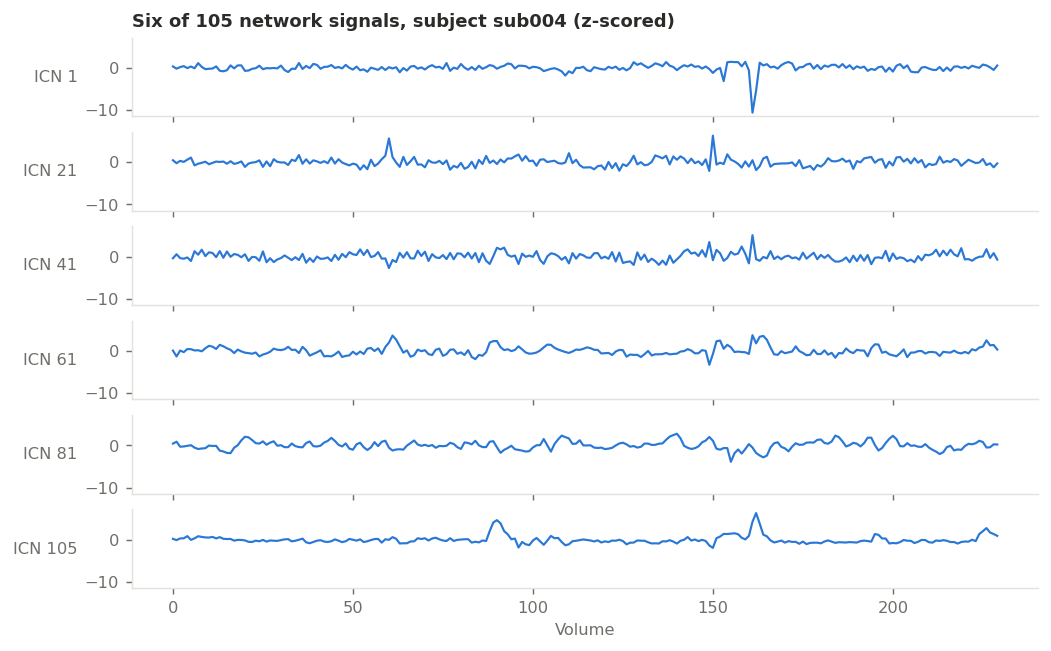

2026-10-30 23:06:44,078 DONE  example_traces (0.8s)


In [7]:
@step
def example_traces():
    sid = next(iter(EXAMPLES.values()))
    x = zscore(TC[sid])
    picks = [0, 20, 40, 60, 80, 104]
    fig, axes = plt.subplots(len(picks), 1, figsize=(9, 5.5), sharex=True, sharey=True)
    for ax, j in zip(axes, picks):
        ax.plot(x[:, j], color=SZ_COLOR, lw=1.2)
        ax.set_ylabel(f"ICN {j + 1}", rotation=0, ha="right", va="center")
        ax.grid(False)
    axes[0].set_title(f"Six of 105 network signals, subject {sid} (z-scored)")
    axes[-1].set_xlabel("Volume")
    save_fig(fig, "sample_traces")

### The whole sample as a picture

Top row: every network over time, where a vertical stripe is a moment many
networks moved together. Bottom row: the same scan collapsed into its FNC,
computed here from the time-courses and shown in file order.

2026-10-30 23:06:44,127 START example_carpets


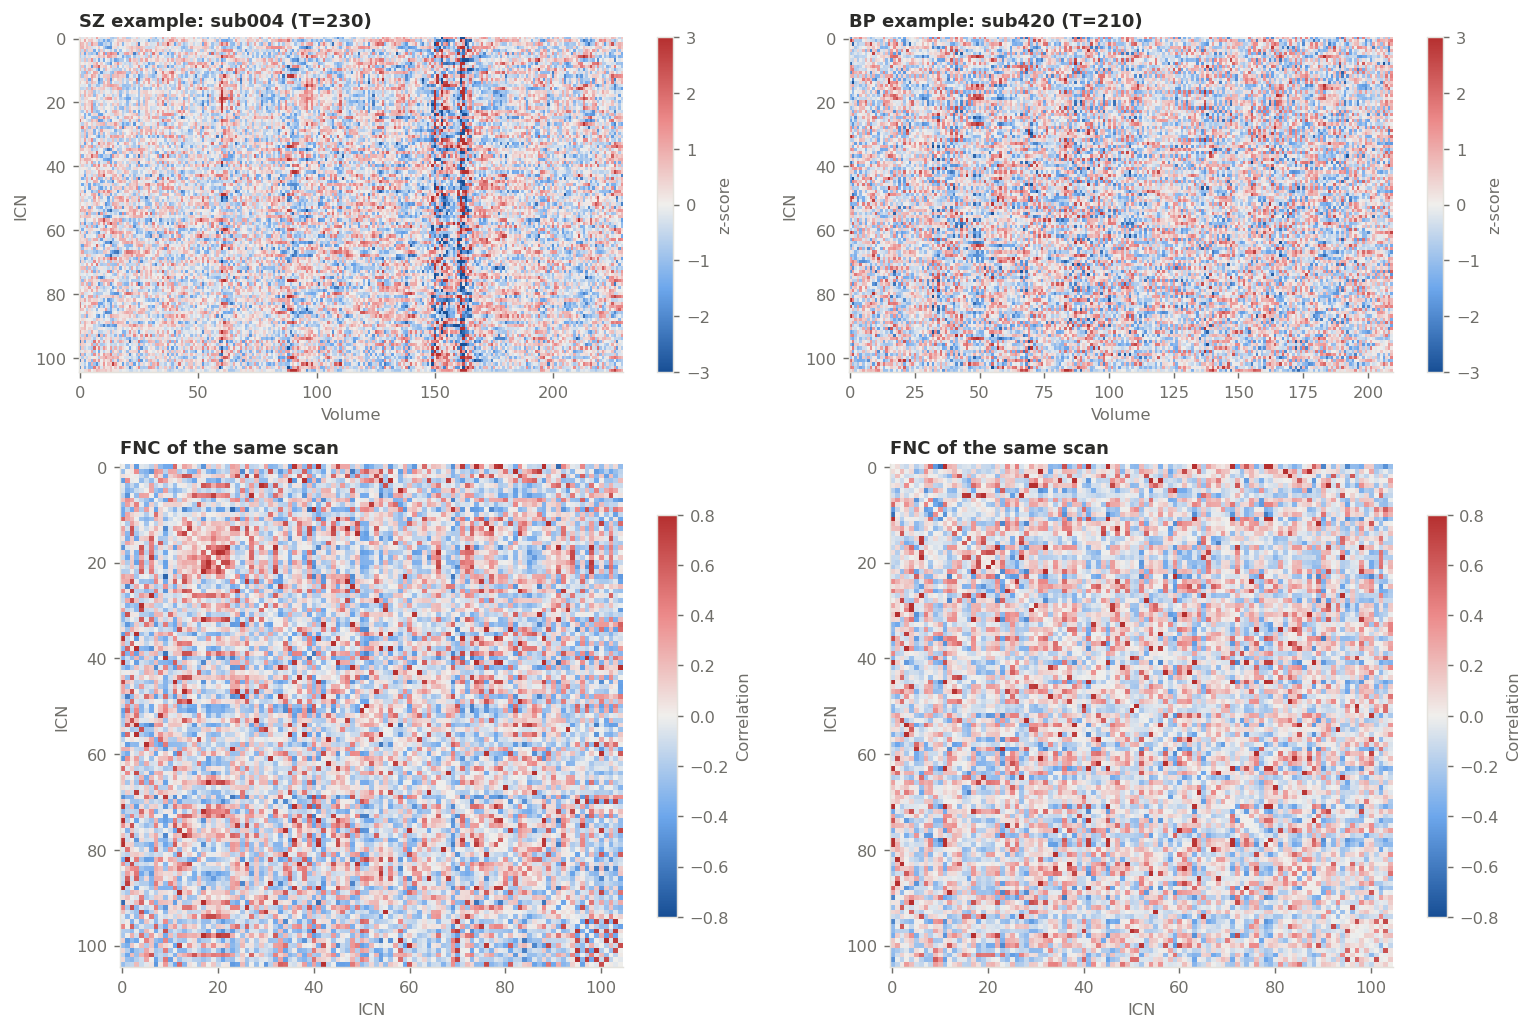

2026-10-30 23:06:45,968 DONE  example_carpets (1.8s)


In [8]:
@step
def example_carpets():
    n = len(EXAMPLES)
    fig, axes = plt.subplots(2, n, figsize=(6 * n, 8), squeeze=False, height_ratios=[1, 1.5])
    for i, (group, sid) in enumerate(EXAMPLES.items()):
        x = zscore(TC[sid])
        top = axes[0, i].imshow(x.T, aspect="auto", cmap=DIV_FNC, vmin=-3, vmax=3, interpolation="nearest")
        axes[0, i].set(title=f"{group} example: {sid} (T={len(x)})", xlabel="Volume", ylabel="ICN")
        axes[0, i].grid(False)
        fig.colorbar(top, ax=axes[0, i], label="z-score")
        r = np.corrcoef(x.T)
        np.fill_diagonal(r, 0)
        bottom = axes[1, i].imshow(r, cmap=DIV_FNC, vmin=-.8, vmax=.8, interpolation="nearest")
        axes[1, i].set(title="FNC of the same scan", xlabel="ICN", ylabel="ICN")
        axes[1, i].grid(False)
        fig.colorbar(bottom, ax=axes[1, i], shrink=.8, label="Correlation")
    fig.tight_layout()
    save_fig(fig, "sample_carpets")

### One subject as a 3D stack

As far as we know this release has no brain volumes, only the 105 signals
extracted from them, so a stack of anatomical slices cannot be drawn. The file
inventory in Part 1 will confirm this. What can be stacked is connectivity:
each slice is the 105 x 105 FNC of one short window, and time runs down through
the stack. If connectivity held still, every slice would look alike. Short
windows are noisy, so slices differ even with no real change.

2026-10-30 23:06:46,045 START example_stack_3d


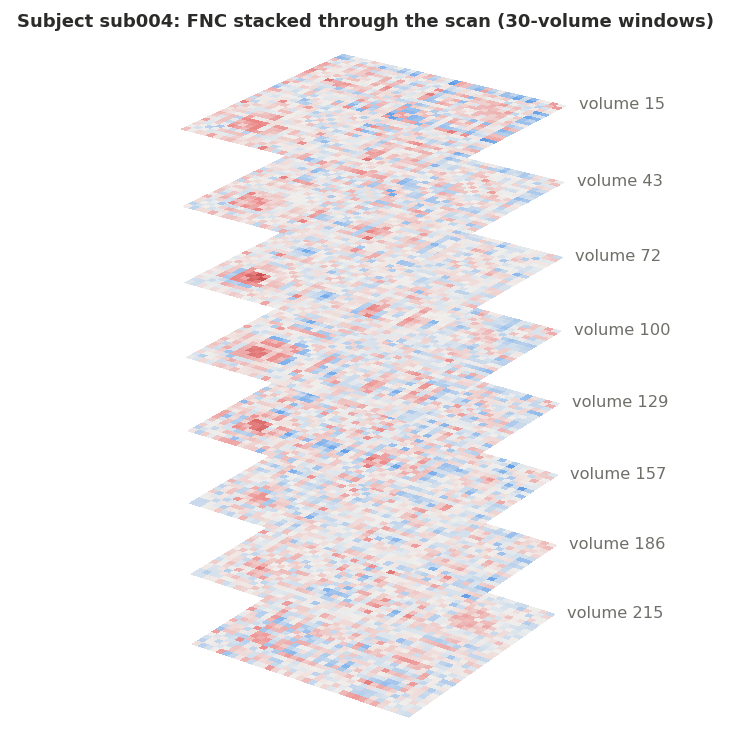

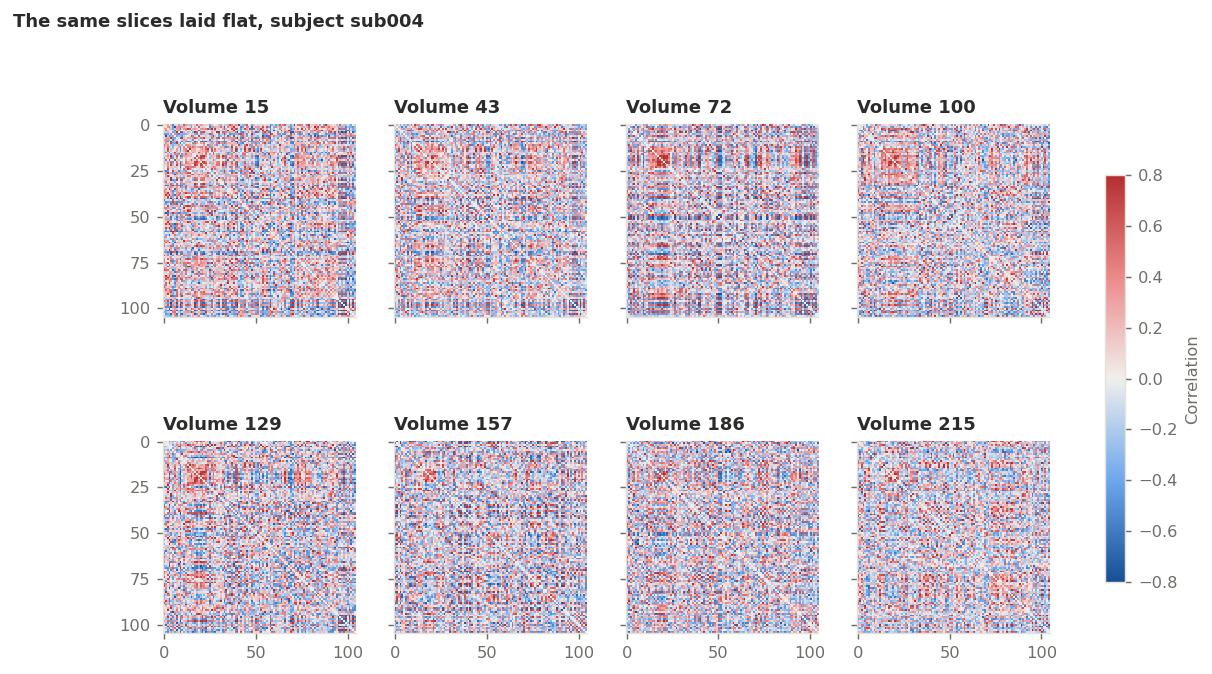

2026-10-30 23:06:51,998 DONE  example_stack_3d (6.0s)


In [9]:
def block_mean(m, size=3):
    """Shrink a 105 x 105 matrix by averaging size x size blocks."""
    n = m.shape[0] // size
    return m[:n * size, :n * size].reshape(n, size, n, size).mean((1, 3))


def window_fnc(x, centre, window):
    start = max(0, min(centre - window // 2, len(x) - window))
    r = np.corrcoef(x[start:start + window].T)
    np.fill_diagonal(r, 0)
    return r


def stack_slices(x, n_slices=8):
    window = min(30, len(x) // 3)
    centres = np.linspace(window // 2, len(x) - window // 2, n_slices).astype(int)
    return window, centres, [window_fnc(x, c, window) for c in centres]


@step
def example_stack_3d():
    sid = next(iter(EXAMPLES.values()))
    window, centres, slices = stack_slices(zscore(TC[sid]))
    limit = plt.Normalize(-.8, .8)
    fig = plt.figure(figsize=(7, 9))
    ax = fig.add_subplot(projection="3d", computed_zorder=False)
    for depth, centre, r in reversed(list(zip(range(len(slices)), centres, slices))):
        small = block_mean(r)
        edges = np.arange(small.shape[0] + 1)
        gx, gy = np.meshgrid(edges, edges)
        ax.plot_surface(gx, gy, np.full(gx.shape, -depth * 18.0), facecolors=DIV_FNC(limit(small)),
                        rstride=1, cstride=1, shade=False, antialiased=False, linewidth=0)
        ax.text(small.shape[0] + 2, small.shape[0], -depth * 18.0, f"volume {centre}", color=MUTED, zorder=100)
    ax.set_box_aspect((1, 1, 1.9))
    ax.view_init(elev=24, azim=-55)
    ax.set_axis_off()
    ax.set_title(f"Subject {sid}: FNC stacked through the scan ({window}-volume windows)")
    save_fig(fig, "sample_stack_3d")

    fig, axes = plt.subplots(2, 4, figsize=(11, 5.8), sharex=True, sharey=True)
    for ax, centre, r in zip(axes.ravel(), centres, slices):
        image = ax.imshow(r, cmap=DIV_FNC, norm=limit, interpolation="nearest")
        ax.set_title(f"Volume {centre}")
        ax.grid(False)
    fig.suptitle(f"The same slices laid flat, subject {sid}", x=.02, ha="left", fontweight="bold", fontsize=10)
    fig.colorbar(image, ax=axes, shrink=.7, label="Correlation")
    save_fig(fig, "sample_stack_flat")

### One slice for every subject

Each tile is one person's whole-scan FNC, in file order, sorted by scan length
within each set. Shared blocks show the common layout, and odd tiles point to
scans worth a closer look. Reading these for group differences is not valid.

2026-10-30 23:06:52,081 START cohort_montage


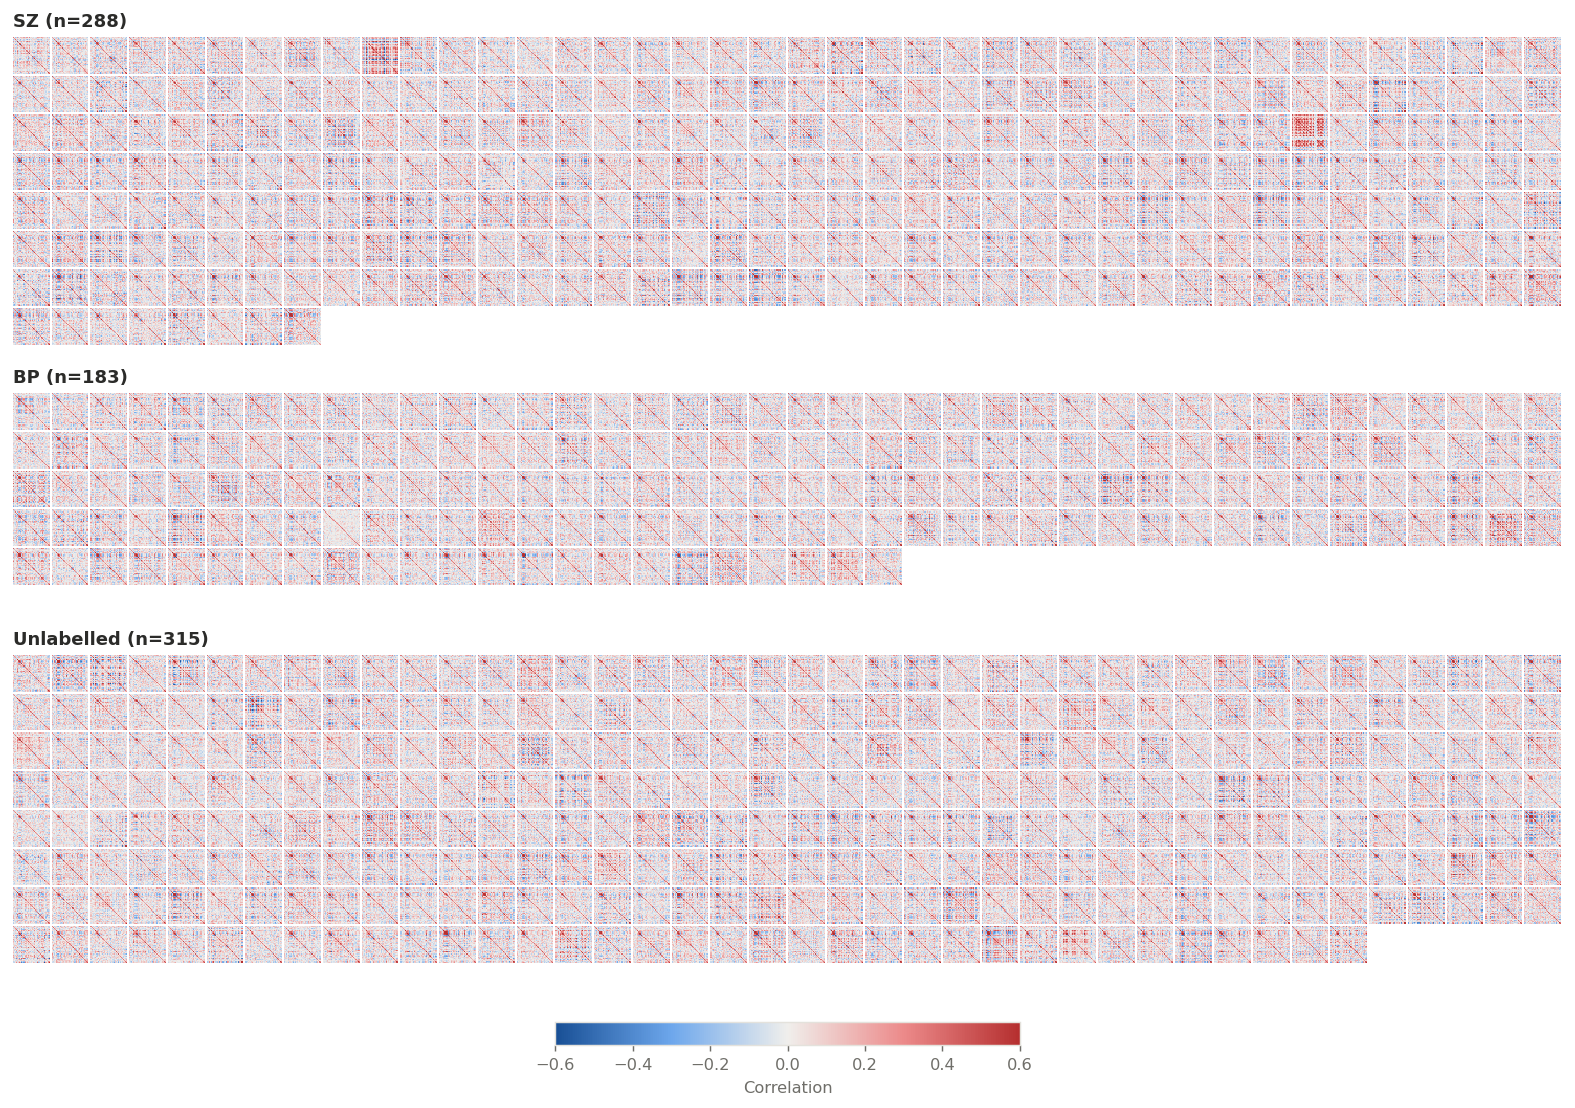

2026-10-30 23:06:55,278 DONE  cohort_montage (3.2s)


In [10]:
def fnc_montage(ids, columns=40, gap=2):
    tiles = [block_mean(np.corrcoef(TC[sid].T)) for sid in ids]
    size = tiles[0].shape[0]
    rows = int(np.ceil(len(tiles) / columns))
    sheet = np.full((rows * (size + gap), columns * (size + gap)), np.nan)
    for k, tile in enumerate(tiles):
        row, column = divmod(k, columns)
        sheet[row * (size + gap):row * (size + gap) + size,
              column * (size + gap):column * (size + gap) + size] = tile
    return sheet, rows


@step
def cohort_montage():
    used = QC[QC["usable"]].sort_values(["T", "subject"])
    sets = [(group, used.loc[used["label"] == group, "subject"].tolist()) for group in GROUP_COLORS]
    sets.append(("Unlabelled", used.loc[used["label"].isna(), "subject"].tolist()))
    sets = [(name, ids) for name, ids in sets if ids]
    sheets = [(name, len(ids), *fnc_montage(ids)) for name, ids in sets]
    cmap = DIV_FNC.with_extremes(bad="white")
    fig, axes = plt.subplots(len(sheets), 1, figsize=(12, 1 + .32 * sum(s[3] for s in sheets) + .3 * len(sheets)),
                             squeeze=False, height_ratios=[s[3] for s in sheets], layout="constrained")
    for ax, (name, n, sheet, _) in zip(axes[:, 0], sheets):
        image = ax.imshow(sheet, cmap=cmap, vmin=-.6, vmax=.6, interpolation="nearest")
        ax.set_title(f"{name} (n={n})")
        ax.set_axis_off()
    fig.colorbar(image, ax=axes, orientation="horizontal", shrink=.3, label="Correlation")
    save_fig(fig, "cohort_fnc_slices")

### Every subject stacked over time

One row per subject, longest scan at the top, coloured by the average of all
105 networks. The white edge on the right is where shorter scans end. A column
running across many rows would mean something tied to scan position.

2026-10-30 23:06:55,500 START cohort_time_stack


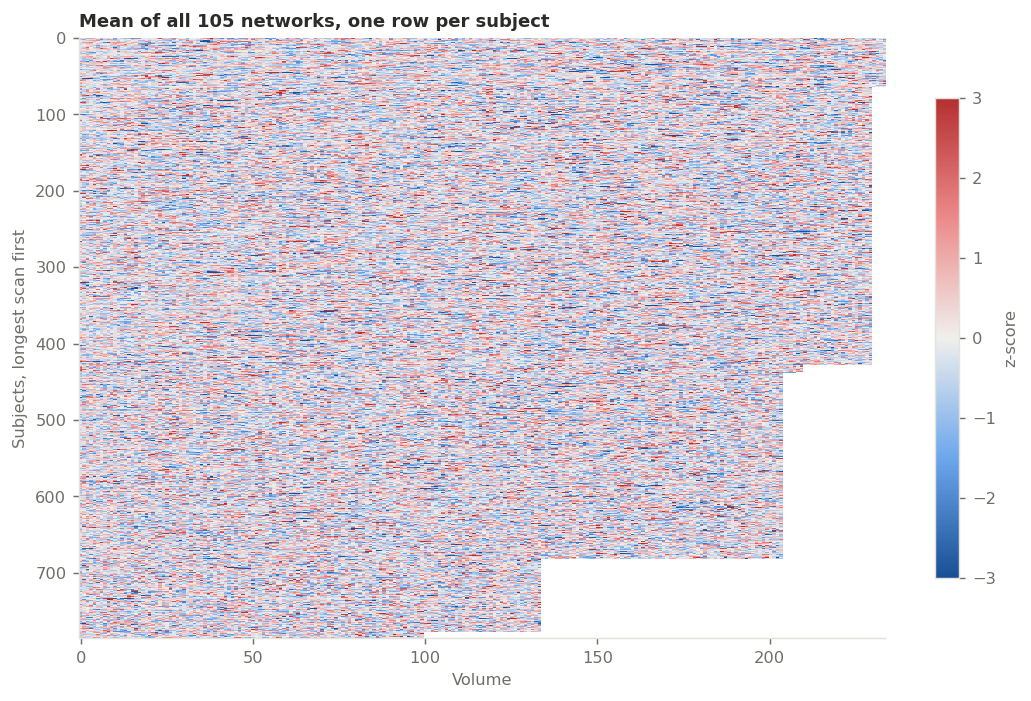

2026-10-30 23:06:56,525 DONE  cohort_time_stack (1.0s)


In [11]:
@step
def cohort_time_stack():
    used = QC[QC["usable"]].sort_values(["T", "subject"], ascending=[False, True])
    sheet = np.full((len(used), used["T"].max()), np.nan)
    for row, sid in enumerate(used["subject"]):
        signal = zscore(TC[sid]).mean(1)
        sheet[row, :len(signal)] = (signal - signal.mean()) / signal.std()
    fig, ax = plt.subplots(figsize=(10, 6))
    image = ax.imshow(sheet, aspect="auto", cmap=DIV_FNC.with_extremes(bad="white"), vmin=-3, vmax=3, interpolation="nearest")
    ax.grid(False)
    ax.set(title="Mean of all 105 networks, one row per subject", xlabel="Volume", ylabel="Subjects, longest scan first")
    fig.colorbar(image, ax=ax, shrink=.8, label="z-score")
    save_fig(fig, "cohort_time_stack")

### What the numbers look like

Left: all values of one sample against a normal curve, which shows tails.
Right: its 5,460 edges, which shows how many connections are strong.

2026-10-30 23:06:56,735 START example_distributions


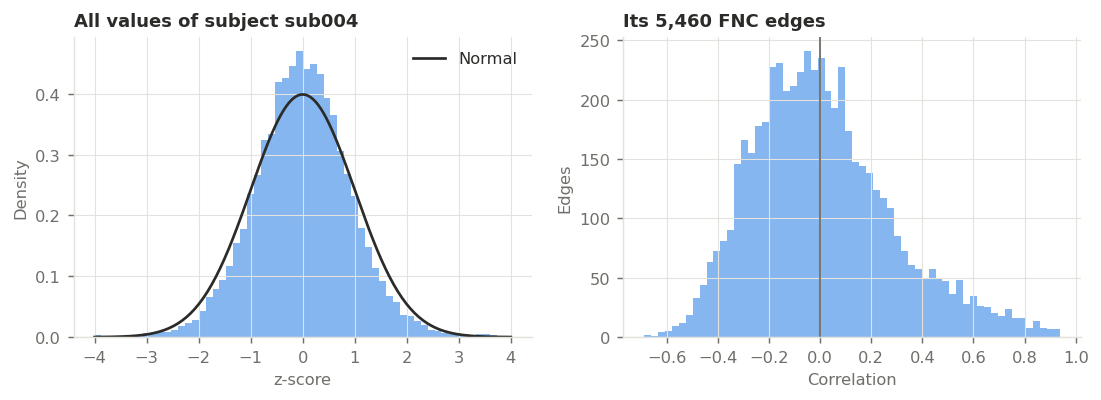

2026-10-30 23:06:57,549 DONE  example_distributions (0.8s)


In [12]:
@step
def example_distributions():
    sid = next(iter(EXAMPLES.values()))
    x = zscore(TC[sid])
    edges = np.corrcoef(x.T)[np.triu_indices(P, 1)]
    SUMMARY["example_edges"] = {
        "subject": sid, "edge_r_quantiles": np.quantile(edges, [.01, .5, .99]).tolist(),
        "share_abs_r_above_0.3": float((np.abs(edges) > .3).mean()),
    }
    grid = np.linspace(-4, 4, 200)
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    axes[0].hist(x.ravel(), bins=60, range=(-4, 4), density=True, color="#86b6ef")
    axes[0].plot(grid, ss.norm.pdf(grid), color=INK, lw=1.5, label="Normal")
    axes[0].set(title=f"All values of subject {sid}", xlabel="z-score", ylabel="Density")
    axes[0].legend()
    axes[1].hist(edges, bins=60, color="#86b6ef")
    axes[1].axvline(0, color=MUTED, lw=1)
    axes[1].set(title="Its 5,460 FNC edges", xlabel="Correlation", ylabel="Edges")
    save_fig(fig, "sample_distributions")

### Does one edge hold still over the scan?

This is the question behind the project, shown for the example's strongest
edge. The line is the correlation in a sliding window. The band is what the
same edge does in phase-randomised copies of the scan, which keep the spectra
and static correlations but have no real change. A line that stays inside the
band could be sampling noise alone, so wiggles are not evidence of a change.

2026-10-30 23:06:57,876 START example_dynamic_edge
2026-10-30 23:06:58,231 {'subject': 'sub004', 'edge': [1, 42], 'static_r': 0.9401889091247259, 'window': 30, 'sliding_sd_observed': 0.07953239558591838, 'sliding_sd_surrogate_median': 0.021779314157136236}


/usr/local/lib/python3.13/dist-packages/numpy/lib/_nanfunctions_impl.py:1650: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


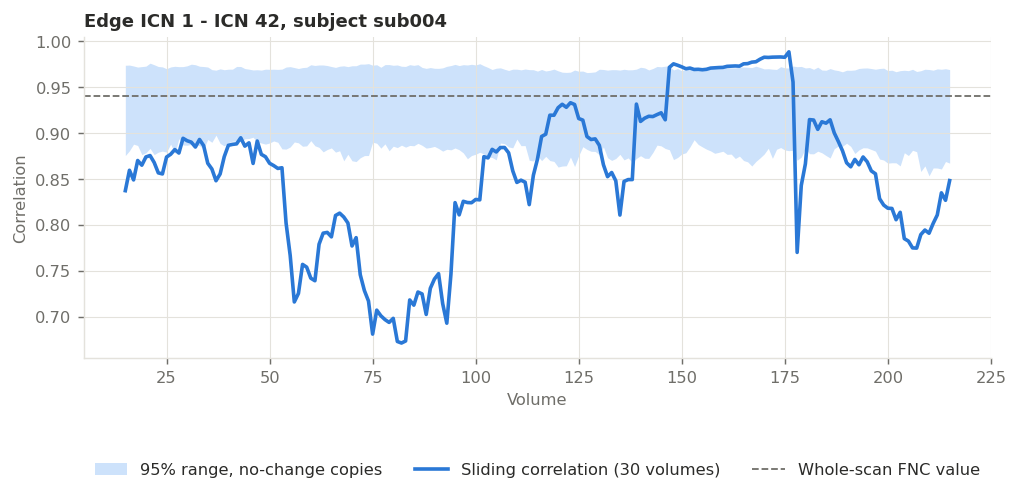

2026-10-30 23:06:58,631 DONE  example_dynamic_edge (0.8s)


In [13]:
def phase_randomise(x, generator):
    """Surrogate with shared random phases, which keeps auto- and cross-spectra."""
    spectrum = np.fft.rfft(x - x.mean(0), axis=0)
    phases = np.exp(2j * np.pi * generator.random(spectrum.shape[0]))
    phases[0] = 1
    return np.fft.irfft(spectrum * phases[:, None], n=len(x), axis=0)


def sliding_corr(a, b, window):
    return pd.Series(a).rolling(window, center=True).corr(pd.Series(b)).to_numpy()


@step
def example_dynamic_edge():
    sid = next(iter(EXAMPLES.values()))
    x = zscore(TC[sid])
    T = len(x)
    window = min(30, T // 3)
    r = np.corrcoef(x.T)
    np.fill_diagonal(r, 0)
    i, j = np.unravel_index(np.abs(r).argmax(), r.shape)
    observed = sliding_corr(x[:, i], x[:, j], window)
    generator = np.random.default_rng(SEED + 1)
    copies = []
    for _ in range(200):
        s = phase_randomise(x, generator)
        copies.append(sliding_corr(s[:, i], s[:, j], window))
    copies = np.array(copies)
    low, high = np.nanquantile(copies, [.025, .975], axis=0)
    SUMMARY["example_dynamic_edge"] = {
        "subject": sid, "edge": [int(i + 1), int(j + 1)], "static_r": float(r[i, j]), "window": window,
        "sliding_sd_observed": float(np.nanstd(observed)),
        "sliding_sd_surrogate_median": float(np.median(np.nanstd(copies, axis=1))),
    }
    log.info("%s", SUMMARY["example_dynamic_edge"])

    fig, ax = plt.subplots(figsize=(9, 3.2))
    time = np.arange(T)
    ax.fill_between(time, low, high, color="#cde2fb", lw=0, label="95% range, no-change copies")
    ax.plot(time, observed, color=SZ_COLOR, label=f"Sliding correlation ({window} volumes)")
    ax.axhline(r[i, j], color=MUTED, lw=1, ls="--", label="Whole-scan FNC value")
    ax.set(title=f"Edge ICN {i + 1} - ICN {j + 1}, subject {sid}", xlabel="Volume", ylabel="Correlation")
    ax.legend(ncols=3, loc="lower center", bbox_to_anchor=(.5, -.42))
    save_fig(fig, "sample_dynamic_edge")

### How alike are two samples?

Each subject's FNC is compared with the average FNC of everyone else. High
similarity means a shared brain layout. The spread shows how much of each
sample is individual.

2026-10-30 23:06:58,827 START between_subject_similarity


similarity:   0%|          | 0/786 [00:00<?, ?it/s]

2026-10-30 23:06:59,739 {'quantiles_5_50_95': [0.667291617256469, 0.7819933310927764, 0.8487228630586213]}


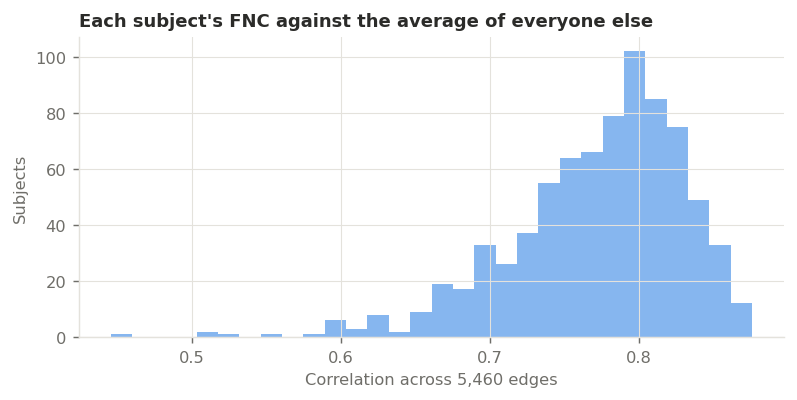

2026-10-30 23:07:00,038 DONE  between_subject_similarity (1.2s)


In [14]:
@step
def between_subject_similarity():
    used = QC[QC["usable"]]
    upper = np.triu_indices(P, 1)
    edges = np.stack([np.arctanh(np.clip(np.corrcoef(TC[sid].T)[upper], -.999999, .999999))
                      for sid in tqdm(used["subject"], desc="similarity")])
    total = edges.sum(0)
    similarity = np.array([np.corrcoef(row, (total - row) / (len(edges) - 1))[0, 1] for row in edges])
    pd.DataFrame({"subject": used["subject"].to_numpy(), "similarity_to_others": similarity}).to_csv(
        OUT / "subject_similarity.csv", index=False)
    SUMMARY["between_subject_similarity"] = {"quantiles_5_50_95": np.quantile(similarity, [.05, .5, .95]).tolist()}
    log.info("%s", SUMMARY["between_subject_similarity"])

    fig, ax = plt.subplots(figsize=(7, 3))
    ax.hist(similarity, bins=30, color="#86b6ef")
    ax.set(title="Each subject's FNC against the average of everyone else", xlabel="Correlation across 5,460 edges", ylabel="Subjects")
    save_fig(fig, "sample_similarity")

## Part 4: properties of the whole dataset

### Scan lengths

2026-10-30 23:07:00,268 START t_distribution
2026-10-30 23:07:00,276 {'min': 100, 'q25': 204.0, 'median': 230.0, 'q75': 230.0, 'max': 234, 'n_unique': 7, 'top_values': {230: 364, 204: 244, 134: 95, 234: 65, 210: 9, 100: 8, 208: 1}, 'p_over_T_median': 0.45652173913043476, 'share_T_below_105': 0.010178117048346057}


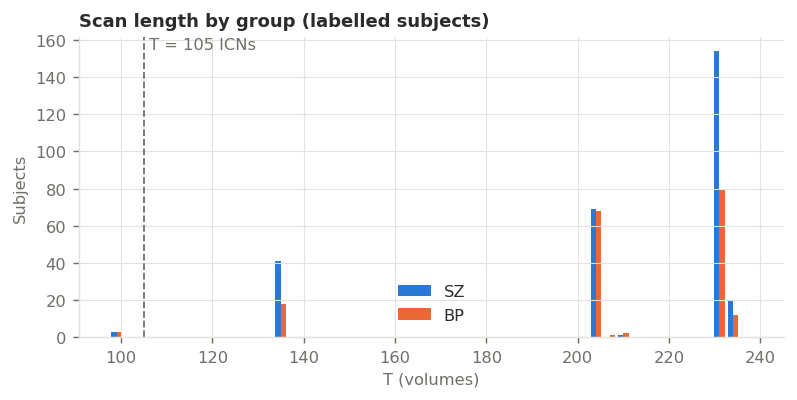

2026-10-30 23:07:00,826 DONE  t_distribution (0.6s)


In [15]:
def t_groups():
    """Exact T when lengths are few (likely protocols), otherwise quartile bins."""
    if QC["T"].nunique() <= 8:
        return QC["T"].astype(str)
    return pd.qcut(QC["T"], 4, duplicates="drop").astype(str)


@step
def t_distribution():
    T = QC["T"]
    SUMMARY["T"] = {
        "min": int(T.min()), "q25": float(T.quantile(.25)), "median": float(T.median()), "q75": float(T.quantile(.75)),
        "max": int(T.max()), "n_unique": int(T.nunique()), "top_values": {int(k): int(v) for k, v in T.value_counts().head(10).items()},
        "p_over_T_median": P / float(T.median()), "share_T_below_105": float((T < P).mean()),
    }
    log.info("%s", SUMMARY["T"])
    QC["T_group"] = t_groups()
    QC.groupby(["split", "T_group"]).size().rename("n").to_csv(OUT / "T_groups.csv")

    fig, ax = plt.subplots(figsize=(7, 3))
    bins = np.arange(T.min() - 2.5, T.max() + 7.5, max(1, (T.max() - T.min()) // 60 + 1))
    data = QC[QC["label"].notna()]
    ax.hist([data.loc[data["label"] == group, "T"] for group in GROUP_COLORS], bins=bins,
            color=list(GROUP_COLORS.values()), label=list(GROUP_COLORS))
    ax.axvline(P, color=MUTED, ls="--", lw=1)
    ax.text(P, ax.get_ylim()[1], " T = 105 ICNs", color=MUTED, va="top")
    ax.set(title="Scan length by group (labelled subjects)", xlabel="T (volumes)", ylabel="Subjects")
    ax.legend()
    save_fig(fig, "T_distribution")

### Scaling and cleaning state

Exactly zero means and unit variances would mean the release was z-scored.

In [16]:
@step
def scaling():
    good = QC["usable"].to_numpy()
    mean, std = FEATURES["icn_mean"][good], FEATURES["icn_std"][good]
    r2, p = FEATURES["drift_r2"][good], FEATURES["drift_p"][good]
    SUMMARY["scaling"] = {
        "share_icn_mean_near_0": float((np.abs(mean) < 1e-6).mean()),
        "share_icn_std_near_1": float((np.abs(std - 1) < 1e-3).mean()),
        "icn_mean_quantiles": np.quantile(mean, [.01, .5, .99]).tolist(),
        "icn_std_quantiles": np.quantile(std, [.01, .5, .99]).tolist(),
        "max_abs_value": float(QC["max_abs"].max()),
    }
    SUMMARY["tails"] = {
        "excess_kurtosis_quantiles": np.nanquantile(FEATURES["excess_kurtosis"][good], [.05, .5, .95]).tolist(),
    }
    SUMMARY["drift"] = {
        "linear_r2_median": float(np.nanmedian(r2)),
        "linear_r2_q95": float(np.nanquantile(r2, .95)),
        "share_icns_p05_ar_adjusted": float(np.nanmean(p < 0.05)),
        "note": "about 0.05 means no drift beyond chance; the test is AR(1)-adjusted",
    }
    log.info("%s\n%s\n%s", SUMMARY["scaling"], SUMMARY["tails"], SUMMARY["drift"])

2026-10-30 23:07:01,027 START scaling
2026-10-30 23:07:01,041 {'share_icn_mean_near_0': 1.0, 'share_icn_std_near_1': 0.0, 'icn_mean_quantiles': [-6.694402267683798e-08, 1.1646722233980772e-13, 6.796828671997669e-08], 'icn_std_quantiles': [0.000808618374077262, 0.9978609595414218, 25.61644979086185], 'max_abs_value': 281.2069091796875}
{'excess_kurtosis_quantiles': [-0.5279815906307456, 0.212311723392125, 7.700496970814182]}
{'linear_r2_median': 0.0, 'linear_r2_q95': 6.661338147750939e-16, 'share_icns_p05_ar_adjusted': 0.0, 'note': 'about 0.05 means no drift beyond chance; the test is AR(1)-adjusted'}
2026-10-30 23:07:01,042 DONE  scaling (0.0s)


### Autocorrelation

`ar1_bc` adds the first-order small-sample correction, so these are the
coefficients to feed the VAR(1) simulation design. A large `ar2_phi2` means
AR(1) alone understates the dependence.

2026-10-30 23:07:01,256 START autocorrelation
2026-10-30 23:07:01,346 {'ar1_bc_quantiles_all': [-0.17061908406564003, 0.16445866677878257, 0.38438353116684154, 0.5807896195128275, 0.7650211454545783], 'ar1_bc_icn_median_range': [0.08604996420444541, 0.7113027713089808], 'ar2_phi2_median': 0.01662182907555146, 'edge_ess_ratio_quantiles': [0.4541791184077959, 0.7118166675173356, 0.9164932721208341], 'mean_ar1_by_T_group': {'100': 0.462, '134': 0.29, '204': 0.299, '208': 0.441, '210': 0.1, '230': 0.391, '234': 0.47}}


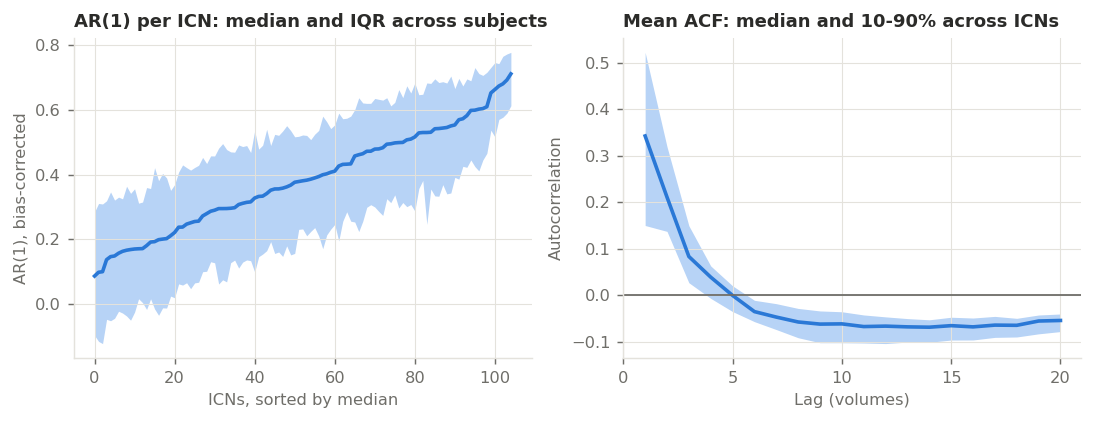

2026-10-30 23:07:01,855 DONE  autocorrelation (0.6s)


In [17]:
@step
def autocorrelation():
    good = QC["usable"].to_numpy()
    ar1 = FEATURES["ar1_bc"][good]
    phi2 = FEATURES["ar2_phi2"][good]
    table = pd.DataFrame({
        "icn": np.arange(1, P + 1),
        "ar1_bc_median": np.nanmedian(ar1, 0),
        "ar1_bc_q25": np.nanquantile(ar1, .25, axis=0), "ar1_bc_q75": np.nanquantile(ar1, .75, axis=0),
        "ar2_phi2_median": np.nanmedian(phi2, 0),
        "excess_kurtosis_median": np.nanmedian(FEATURES["excess_kurtosis"][good], 0),
    })
    table.to_csv(OUT / "icn_autocorrelation.csv", index=False)
    pd.DataFrame(FEATURES["acf_mean"], columns=[f"icn{i}" for i in range(1, P + 1)],
                 index=pd.RangeIndex(1, ACF_LAGS + 1, name="lag")).to_csv(OUT / "icn_mean_acf.csv")

    by_group = QC[good].groupby("T_group")["mean_ar1_bc"].describe()[["count", "mean", "std"]]
    by_group.to_csv(OUT / "ar1_by_T_group.csv")
    SUMMARY["autocorrelation"] = {
        "ar1_bc_quantiles_all": np.nanquantile(ar1, [.05, .25, .5, .75, .95]).tolist(),
        "ar1_bc_icn_median_range": [float(table["ar1_bc_median"].min()), float(table["ar1_bc_median"].max())],
        "ar2_phi2_median": float(np.nanmedian(phi2)),
        "edge_ess_ratio_quantiles": QC["ess_ratio"].quantile([.05, .5, .95]).tolist(),
        "mean_ar1_by_T_group": by_group["mean"].round(3).to_dict(),
    }
    log.info("%s", SUMMARY["autocorrelation"])

    order = table.sort_values("ar1_bc_median").reset_index(drop=True)
    acf = FEATURES["acf_mean"]
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
    axes[0].fill_between(order.index, order["ar1_bc_q25"], order["ar1_bc_q75"], color="#b7d3f6", lw=0)
    axes[0].plot(order.index, order["ar1_bc_median"], color=SZ_COLOR)
    axes[0].set(title="AR(1) per ICN: median and IQR across subjects", xlabel="ICNs, sorted by median", ylabel="AR(1), bias-corrected")
    lags = np.arange(1, ACF_LAGS + 1)
    axes[1].fill_between(lags, np.quantile(acf, .1, axis=1), np.quantile(acf, .9, axis=1), color="#b7d3f6", lw=0)
    axes[1].plot(lags, np.median(acf, axis=1), color=SZ_COLOR)
    axes[1].axhline(0, color=MUTED, lw=1)
    axes[1].set(title="Mean ACF: median and 10-90% across ICNs", xlabel="Lag (volumes)", ylabel="Autocorrelation",
                xticks=np.arange(0, ACF_LAGS + 1, 5))
    save_fig(fig, "autocorrelation")

### Spectra

Frequencies are in cycles per TR, since TR is not known yet. A hard drop in
power reveals band-pass filtering. Different spectra across T groups would
suggest different protocols pooled in one release.

2026-10-30 23:07:02,068 START spectra


spectra:   0%|          | 0/786 [00:00<?, ?it/s]

2026-10-30 23:07:04,058 {'cycles_per_TR_holding_share_of_power': {'0.5': 0.125, '0.9': 0.421875, '0.95': 0.4609375, '0.99': 0.4921875}, 'share_of_power_above_0.25': 0.2879618348296283}


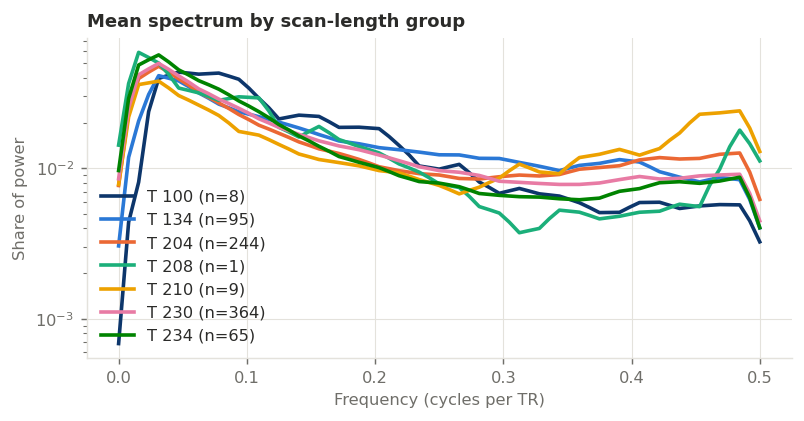

2026-10-30 23:07:04,732 DONE  spectra (2.7s)


In [18]:
@step
def spectra():
    grid = np.linspace(0, 0.5, 65)
    groups = {}
    icn_power = np.zeros((P, grid.size))
    used = QC[QC["usable"]]
    for sid, group in tqdm(zip(used["subject"], used["T_group"]), total=len(used), desc="spectra"):
        x = TC[sid] - TC[sid].mean(0)
        x = x / x.std(0)
        freq, power = scipy.signal.welch(x, nperseg=min(64, len(x)), axis=0)
        resampled = np.stack([np.interp(grid, freq, power[:, j]) for j in range(P)], axis=1).T
        resampled /= resampled.sum(1, keepdims=True)
        icn_power += resampled
        mean, n = groups.get(group, (0, 0))
        groups[group] = (mean + resampled.mean(0), n + 1)
    icn_power /= len(used)
    mean_power = icn_power.mean(0)
    cumulative = np.cumsum(mean_power) / mean_power.sum()
    pd.DataFrame(icn_power, columns=[f"f{f:.4f}" for f in grid]).to_csv(OUT / "icn_power_spectra.csv", index=False)
    SUMMARY["spectra"] = {
        "cycles_per_TR_holding_share_of_power": {str(q): float(grid[np.searchsorted(cumulative, q)]) for q in (.5, .9, .95, .99)},
        "share_of_power_above_0.25": float(mean_power[grid > 0.25].sum() / mean_power.sum()),
    }
    log.info("%s", SUMMARY["spectra"])

    fig, ax = plt.subplots(figsize=(7, 3.2))
    shades = ["#0d366b", "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]
    for (group, (total, n)), color in zip(sorted(groups.items()), shades):
        ax.semilogy(grid, total / n, color=color, label=f"T {group} (n={n})")
    ax.set(title="Mean spectrum by scan-length group", xlabel="Frequency (cycles per TR)", ylabel="Share of power")
    ax.legend()
    save_fig(fig, "spectra")

### Is the supplied FNC the plain correlation of the time-courses?

A match at any setting proves the two files share ICN order, and shows how
the 5,460 edges are vectorised. This is the order the edge tests will need.

In [19]:
@step
def fnc_vs_timecourses():
    shared = sorted(set(FNC) & set(QC.loc[QC["usable"], "subject"]))
    if not shared:
        SUMMARY["fnc"] = {"note": "no subject has both FNC and time-courses"}
        return
    picks = rng.choice(shared, size=min(50, len(shared)), replace=False)
    upper = np.triu_indices(P, 1)
    lower = np.tril_indices(P, -1)
    scores = {}
    for sid in picks:
        r = np.corrcoef(TC[sid].T)
        given = FNC[sid]
        vec = {"matrix_upper": given[upper]} if given.ndim == 2 else {"vec": given}
        for shape_name, v in vec.items():
            for tri_name, idx in (("upper_rowwise", upper), ("lower_rowwise", lower)):
                for scale, values in (("pearson_r", r[idx]), ("fisher_z", np.arctanh(np.clip(r[idx], -.999999, .999999)))):
                    key = f"{shape_name}/{tri_name}/{scale}"
                    scores.setdefault(key, []).append(
                        (np.corrcoef(v, values)[0, 1], np.median(np.abs(v - values)))
                    )
    table = pd.DataFrame(
        {k: {"median_corr": np.median([s[0] for s in v]), "median_abs_diff": np.median([s[1] for s in v])}
         for k, v in scores.items()}
    ).T.sort_values(["median_corr", "median_abs_diff"], ascending=[False, True])
    table.to_csv(OUT / "fnc_match.csv")
    log.info("\n%s", table.to_string())
    SUMMARY["fnc"] = {
        "n_with_fnc": len(FNC), "stored_as": "matrix" if FNC[shared[0]].ndim == 2 else "vector",
        "best_match": table.index[0], **table.iloc[0].round(5).to_dict(),
    }

2026-10-30 23:07:04,939 START fnc_vs_timecourses
2026-10-30 23:07:05,105 
                             median_corr  median_abs_diff
vec/upper_rowwise/fisher_z      0.859418         0.108097
vec/upper_rowwise/pearson_r     0.858660         0.097777
vec/lower_rowwise/fisher_z      0.006213         0.251673
vec/lower_rowwise/pearson_r     0.004340         0.246732
2026-10-30 23:07:05,108 DONE  fnc_vs_timecourses (0.2s)


### Covariance structure

When T is below 105 the sample correlation is singular, which limits every
plain inverse. A dominant first eigenvalue is the global signal, and it can
drive apparent "connectivity changes" across all edges at once.

In [20]:
MEAN_Z = None


@step
def covariance_structure():
    global MEAN_Z
    used = QC[QC["usable"]]
    z_sum = np.zeros((P, P))
    rows = []
    for sid in tqdm(used["subject"], desc="eig"):
        r = np.corrcoef(TC[sid].T)
        eig = np.linalg.eigvalsh(r)[::-1]
        share = np.cumsum(eig) / eig.sum()
        rows.append({"subject": sid, "top1_share": share[0], "top5_share": share[4],
                     "n_eig_90": int(np.searchsorted(share, .9) + 1), "rank": int((eig > 1e-8).sum())})
        np.fill_diagonal(r, 0)
        z_sum += np.arctanh(np.clip(r, -.999999, .999999))
    MEAN_Z = z_sum / len(used)
    np.save(OUT / "mean_fnc_z.npy", MEAN_Z)
    eig = pd.DataFrame(rows)
    eig.to_csv(OUT / "subject_eigen.csv", index=False)
    QC[["top1_share"]] = QC[["subject"]].merge(eig, on="subject", how="left")[["top1_share"]]
    SUMMARY["covariance"] = {
        "top1_share_quantiles": eig["top1_share"].quantile([.05, .5, .95]).tolist(),
        "top5_share_median": float(eig["top5_share"].median()),
        "n_eig_for_90pct_median": float(eig["n_eig_90"].median()),
        "share_rank_deficient": float((eig["rank"] < P).mean()),
        "mean_fnc_z_offdiag": [float(MEAN_Z[np.triu_indices(P, 1)].mean()), float(MEAN_Z[np.triu_indices(P, 1)].std())],
    }
    log.info("%s", SUMMARY["covariance"])

2026-10-30 23:07:05,364 START covariance_structure


eig:   0%|          | 0/786 [00:00<?, ?it/s]

2026-10-30 23:07:07,086 {'top1_share_quantiles': [0.14752722566586404, 0.20270270533660134, 0.31240348230237497], 'top5_share_median': 0.5946468752272704, 'n_eig_for_90pct_median': 19.0, 'share_rank_deficient': 0.010178117048346057, 'mean_fnc_z_offdiag': [0.03699451377430077, 0.27052711946626945]}
2026-10-30 23:07:07,088 DONE  covariance_structure (1.7s)


### ICN order and a provisional domain map

The published sources disagree on the domain grouping (6 vs 7 domains), and
none we could reach gives per-domain counts for this release. So the map is
measured here: if the file order is by domain, mean FNC shows contiguous
blocks. Dynamic programming finds the best k contiguous blocks, a shuffled ICN
order gives the null, and an unconstrained clustering is compared against it.
These blocks are unnamed; names come later from the NeuroMark template.

2026-10-30 23:07:07,345 START icn_order
2026-10-30 23:07:07,987 
   k    gain  null_mean  null_max  ari_blocks_vs_clusters          block_sizes
0  5  54.182     34.376    70.895                   0.026         4-29-57-4-11
1  6  54.824     36.192    88.813                   0.007       3-8-22-57-4-11
2  7  56.090     38.075    82.491                   0.026     4-3-4-22-57-4-11
3  8  57.288     39.104    79.298                   0.073  4-29-31-5-2-19-4-11


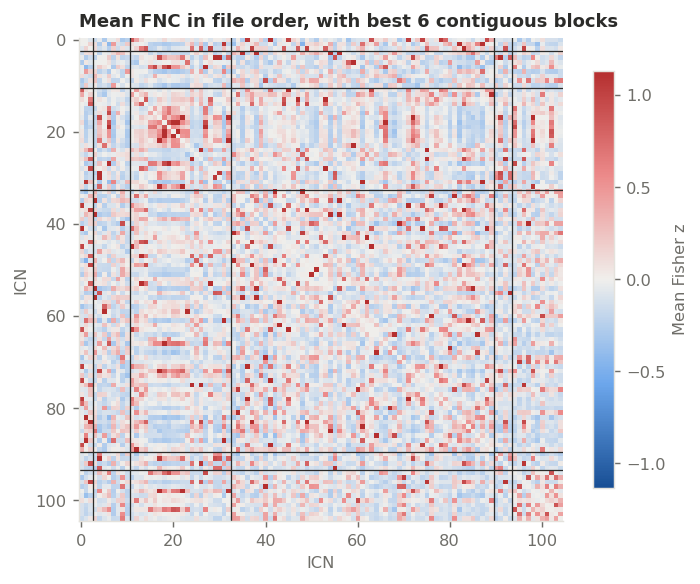

2026-10-30 23:07:08,390 DONE  icn_order (1.0s)


In [21]:
def block_gain(m):
    """G[i, j]: total of m over upper-triangle cells inside ICNs i..j-1."""
    prefix = np.zeros((P + 1, P + 1))
    prefix[1:, 1:] = m.cumsum(0).cumsum(1)
    d = np.diag(prefix)
    gain = (d[None, :] + d[:, None] - prefix - prefix.T) / 2
    gain[np.tril_indices(P + 1)] = -np.inf
    return gain


def best_blocks(m, k):
    gain = block_gain(m)
    best = gain[0].copy()
    back = []
    for _ in range(k - 1):
        scores = best[:, None] + gain
        back.append(scores.argmax(0))
        best = scores.max(0)
    edges = [P]
    for pointers in reversed(back):
        edges.append(int(pointers[edges[-1]]))
    return float(best[P]), [0] + sorted(edges)


def block_labels(edges):
    return np.repeat(np.arange(len(edges) - 1), np.diff(edges))


@step
def icn_order():
    z = MEAN_Z - MEAN_Z[np.triu_indices(P, 1)].mean()
    np.fill_diagonal(z, 0)
    linkage = sch.linkage(MEAN_Z[np.triu_indices(P, 1)] * -1 + MEAN_Z.max(), method="average")
    rows = []
    maps = {"icn": np.arange(1, P + 1)}
    for k in (5, 6, 7, 8):
        gain, starts = best_blocks(z, k)
        blocks = block_labels(starts)
        null = []
        for _ in range(200):
            perm = rng.permutation(P)
            null.append(best_blocks(z[np.ix_(perm, perm)], k)[0])
        clusters = sch.fcluster(linkage, k, "maxclust")
        rows.append({"k": k, "gain": gain, "null_mean": np.mean(null), "null_max": np.max(null),
                     "ari_blocks_vs_clusters": adjusted_rand_score(blocks, clusters),
                     "block_sizes": "-".join(map(str, np.bincount(blocks)))})
        maps[f"block_k{k}"] = blocks + 1
        maps[f"cluster_k{k}"] = clusters
    table = pd.DataFrame(rows)
    table.to_csv(OUT / "icn_order_blocks.csv", index=False)
    pd.DataFrame(maps).to_csv(OUT / "icn_provisional_blocks.csv", index=False)
    SUMMARY["icn_order"] = {
        "file_order_looks_domain_sorted": bool((table["gain"] > table["null_max"]).all()),
        "table": table.round(3).to_dict("records"),
    }
    log.info("\n%s", table.round(3).to_string())

    limit = np.quantile(np.abs(MEAN_Z), .99)
    fig, ax = plt.subplots(figsize=(6, 5.2))
    image = ax.imshow(MEAN_Z, cmap=DIV_FNC, vmin=-limit, vmax=limit, interpolation="nearest")
    for start in np.flatnonzero(np.diff(maps["block_k6"])) + 0.5:
        ax.axhline(start, color=INK, lw=0.7)
        ax.axvline(start, color=INK, lw=0.7)
    ax.grid(False)
    ax.set(title="Mean FNC in file order, with best 6 contiguous blocks", xlabel="ICN", ylabel="ICN")
    fig.colorbar(image, ax=ax, shrink=0.8, label="Mean Fisher z")
    save_fig(fig, "mean_fnc")

### Position in the scan and frame-level spikes

Motion may not be released, so a DVARS-style measure stands in: the size of
each volume-to-volume jump. Spikes and start-of-scan transients can both look
like covariance change points, so we need their rate before detection.

2026-10-30 23:07:08,618 START scan_position_and_spikes


frames:   0%|          | 0/786 [00:00<?, ?it/s]

2026-10-30 23:07:09,041 {'first_5_vs_1': 0.8642618434424374, 'last_5_vs_1': 1.0873005175369141, 'share_scans_with_spike': 0.6590330788804071, 'median_spikes': 2.0, 'q95_spikes': 11.75}


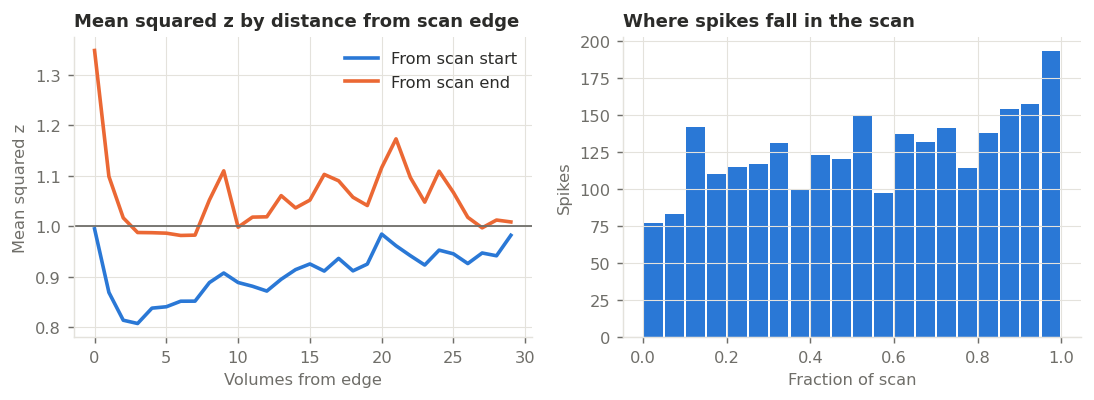

2026-10-30 23:07:09,626 DONE  scan_position_and_spikes (1.0s)


In [22]:
@step
def scan_position_and_spikes():
    used = QC[QC["usable"]]
    n_edge = 30
    from_start, from_end = np.zeros(n_edge), np.zeros(n_edge)
    spikes = []
    spike_position = np.zeros(20)
    for sid in tqdm(used["subject"], desc="frames"):
        x = (TC[sid] - TC[sid].mean(0)) / TC[sid].std(0)
        energy = (x ** 2).mean(1)
        from_start += energy[:n_edge]
        from_end += energy[-n_edge:][::-1]
        dvars = np.sqrt((np.diff(x, axis=0) ** 2).mean(1))
        mad = np.median(np.abs(dvars - np.median(dvars))) * 1.4826
        where = np.flatnonzero((dvars - np.median(dvars)) / mad > 5)
        spikes.append(len(where))
        if len(where):
            np.add.at(spike_position, (where * 20 / len(dvars)).astype(int), 1)
    from_start /= len(used)
    from_end /= len(used)
    QC.loc[QC["usable"], "n_spikes"] = spikes
    spikes = np.array(spikes)
    SUMMARY["scan_position"] = {
        "first_5_vs_1": float(from_start[:5].mean()), "last_5_vs_1": float(from_end[:5].mean()),
        "share_scans_with_spike": float((spikes > 0).mean()), "median_spikes": float(np.median(spikes)),
        "q95_spikes": float(np.quantile(spikes, .95)),
    }
    log.info("%s", SUMMARY["scan_position"])

    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    axes[0].plot(np.arange(n_edge), from_start, color=SZ_COLOR, label="From scan start")
    axes[0].plot(np.arange(n_edge), from_end, color=BP_COLOR, label="From scan end")
    axes[0].axhline(1, color=MUTED, lw=1)
    axes[0].set(title="Mean squared z by distance from scan edge", xlabel="Volumes from edge", ylabel="Mean squared z")
    axes[0].legend()
    axes[1].bar((np.arange(20) + .5) / 20, spike_position, width=.045, color=SZ_COLOR)
    axes[1].set(title="Where spikes fall in the scan", xlabel="Fraction of scan", ylabel="Spikes")
    save_fig(fig, "scan_position")

### Which M and Delta can the scans support?

The Phase 0 exit criterion. A subject can only show one change point when
T >= M + 2 Delta. `dz_se` is the standard error of a Fisher-z edge difference
between two segments of length Delta after autocorrelation, so it shows how
large an edge change has to be before Delta can resolve it.

In [23]:
@step
def feasibility():
    used = QC[QC["usable"]]
    train = used[used["split"] == "train"]
    test = used[used["split"] == "test"]
    ratio = float(used["ess_ratio"].median())
    rows = []
    for M in M_GRID:
        for delta in DELTA_GRID:
            need = M + 2 * delta
            row = {"M": M, "Delta": delta, "T_needed": need, "p_over_M": P / M,
                   "train_kept": int((train["T"] >= need).sum()), "train_share": float((train["T"] >= need).mean()),
                   "test_kept": int((test["T"] >= need).sum())}
            for group in GROUP_COLORS:
                row[f"{group}_kept"] = int((train.loc[train["label"] == group, "T"] >= need).sum())
            n_eff = delta * ratio
            row["Delta_eff"] = n_eff
            row["dz_se"] = np.sqrt(2 / (n_eff - 3)) if n_eff > 3 else np.nan
            rows.append(row)
    table = pd.DataFrame(rows)
    table.to_csv(OUT / "feasibility_M_Delta.csv", index=False)
    SUMMARY["feasibility"] = table.round(3).to_dict("records")
    log.info("\n%s", table.round(3).to_string())

2026-10-30 23:07:09,847 START feasibility
2026-10-30 23:07:09,870 
     M  Delta  T_needed  p_over_M  train_kept  train_share  test_kept  SZ_kept  BP_kept  Delta_eff  dz_se
0   30     30        90      3.50         471        1.000        315      288      183     21.355  0.330
1   30     60       150      3.50         406        0.862        277      244      162     42.709  0.224
2   30    120       270      3.50           0        0.000          0        0        0     85.418  0.156
3   60     30       120      1.75         465        0.987        313      285      180     21.355  0.330
4   60     60       180      1.75         406        0.862        277      244      162     42.709  0.224
5   60    120       300      1.75           0        0.000          0        0        0     85.418  0.156
6  100     30       160      1.05         406        0.862        277      244      162     21.355  0.330
7  100     60       220      1.05         265        0.563        164      174       

### Group confounds (descriptive only)

Not a diagnostic comparison. It checks whether nuisance properties differ by
group: any that do have to be modelled in the Phase 6 exploratory group view.

In [24]:
@step
def group_confounds():
    train = QC[QC["usable"] & QC["label"].isin(GROUP_COLORS)]
    if train["label"].nunique() < 2:
        SUMMARY["group_confounds"] = {"note": "fewer than two groups labelled"}
        return
    rows = []
    for col in ("T", "mean_ar1_bc", "ess_ratio", "top1_share", "n_spikes", "median_kurtosis", "drift_frac_p05"):
        if col not in train:
            continue
        sz = train.loc[train["label"] == "SZ", col].dropna()
        bp = train.loc[train["label"] == "BP", col].dropna()
        u = ss.mannwhitneyu(sz, bp)
        rows.append({"measure": col, "SZ_median": sz.median(), "BP_median": bp.median(),
                     "auc_SZ_over_BP": u.statistic / (len(sz) * len(bp)), "p": u.pvalue})
    table = pd.DataFrame(rows)
    table.to_csv(OUT / "group_confounds.csv", index=False)
    crosstab = pd.crosstab(train["T_group"], train["label"])
    crosstab.to_csv(OUT / "T_group_by_label.csv")
    chi2 = ss.chi2_contingency(crosstab) if crosstab.shape[0] > 1 else None
    SUMMARY["group_confounds"] = {"table": table.round(4).to_dict("records"),
                                  "T_group_chi2_p": None if chi2 is None else float(chi2.pvalue)}
    log.info("\n%s\n%s", table.round(4).to_string(), crosstab.to_string())

2026-10-30 23:07:10,105 START group_confounds
2026-10-30 23:07:10,152 
           measure  SZ_median  BP_median  auc_SZ_over_BP       p
0                T   230.0000   210.0000          0.5346  0.1706
1      mean_ar1_bc     0.3678     0.3585          0.5099  0.7167
2        ess_ratio     0.7039     0.7321          0.4580  0.1240
3       top1_share     0.2085     0.1960          0.5777  0.0045
4         n_spikes     2.0000     1.0000          0.5381  0.1536
5  median_kurtosis     0.2141     0.1305          0.5370  0.1760
6   drift_frac_p05     0.0000     0.0000          0.5000  1.0000
label    BP   SZ
T_group         
100       3    3
134      18   41
204      68   69
208       1    0
210       2    1
230      79  154
234      12   20
2026-10-30 23:07:10,153 DONE  group_confounds (0.0s)


## Package the results

In [25]:
def as_json(value):
    if isinstance(value, (np.integer, np.bool_)):
        return value.item()
    if isinstance(value, np.floating):
        return float(value)
    return str(value)


@step
@always
def package():
    if QC is not None:
        QC.to_csv(OUT / "subject_qc.csv", index=False)
    (OUT / "audit_summary.json").write_text(json.dumps(SUMMARY, indent=2, default=as_json))
    archive = shutil.make_archive(str(WORK_ROOT / "01-audit-results"), "zip", OUT)
    log.info("wrote %s (%.1f MB)", archive, Path(archive).stat().st_size / 1e6)
    log.info("sections failed: %s", SUMMARY["sections_failed"] or "none")
    print(json.dumps(SUMMARY, indent=2, default=as_json)[:12000])

2026-10-30 23:07:10,379 START package
2026-10-30 23:07:10,690 wrote /kaggle/working/01-audit-results.zip (5.0 MB)
2026-10-30 23:07:10,692 sections failed: none
{
  "seed": 20261030,
  "sections_failed": [],
  "n_files": 3144,
  "file_patterns": {
    "competitions/psychosis-classification-with-rsfmri/data/test/#/fnc.mat": 315,
    "competitions/psychosis-classification-with-rsfmri/data/test/#/fnc.npy": 315,
    "competitions/psychosis-classification-with-rsfmri/data/test/#/icn_tc.mat": 315,
    "competitions/psychosis-classification-with-rsfmri/data/test/#/icn_tc.npy": 315,
    "competitions/psychosis-classification-with-rsfmri/data/train/SZ/#/icn_tc.npy": 288,
    "competitions/psychosis-classification-with-rsfmri/data/train/SZ/#/icn_tc.mat": 288,
    "competitions/psychosis-classification-with-rsfmri/data/train/SZ/#/fnc.npy": 288,
    "competitions/psychosis-classification-with-rsfmri/data/train/SZ/#/fnc.mat": 288,
    "competitions/psychosis-classification-with-rsfmri/data/train/BP/